In [1]:
# Notebook-ready script
# ---------------------
# Reads a CSV with model-selection results and generates two LaTeX booktabs tables:
#   1) LLM mapper
#   2) MultiStep mapper
#
# Layout: datasets as row groups, metrics as columns.
# Rows = models, Groups = datasets, Columns = 3 metrics.

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import matplotlib.colors as mcolors

# ============================================================
# 1) CONFIGURATION YOU MAY WANT TO EDIT
# ============================================================

CSV_PATH = "results_summary_all.csv"   # change if needed
ONLY_SUCCESS = True
DECIMALS = 2

# Metrics to show in the table.
# "kind" controls how the column is rendered:
#   - "single": one numeric column
#   - "mean_std": render as "mean ± std", ranked by the mean
METRICS = [
    {
        "key": "constraint_exact_f1",
        "label": "Constraint\nExact F1",
        "kind": "single",
    },
    {
        "key": "pairwise_viol_f1",
        "label": "Pairwise Viol.\nF1",
        "kind": "mean_std",
        "mean_col": "pairwise_viol_f1_mean",
        "std_col": "pairwise_viol_f1_std",
    },
    {
        "key": "agg_viol_f1",
        "label": "Aggregate\nViol. F1",
        "kind": "single",
    },
]

# Order of implementations in output
IMPLEMENTATION_ORDER = ["llm", "multi_step_refinement"]

# Order of datasets in output; any dataset not listed here will be appended alphabetically
DATASET_ORDER = [
    "hospital",
    "restaurant",
    "sisu",
    "tax",
]

# Order of models in output; any model not listed here will be appended alphabetically
MODEL_ORDER = [
    "mistral-small-2506",
    "mistral-large-2512",
    "gpt-5-mini",
    "gpt-5",
    "llama-3.3-70b-versatile",
]

# Pretty names used in the table rows
MODEL_DISPLAY = {
    "mistral-small-2506":      "Mistral-Small",
    "mistral-large-2512":      "Mistral-Large",
    "llama-3.3-70b-versatile": "Llama 3.3",
    "gpt-5-mini":              "GPT-5 mini",
    "gpt-5":                   "GPT-5",
}

# Pretty dataset names used in row-group headers
DATASET_DISPLAY = {
    "tax":        "Tax",
    "hospital":   "Hospital",
    "restaurant": "Restaurant",
    "sisu":       "SISU",
}

# Pretty implementation names used in captions / labels / headings
IMPLEMENTATION_DISPLAY = {
    "llm": "Single-Prompt",
    "multi_step_refinement": "MultiStep",
}

# Optional: if you want to override row grouping by implementation based on variant_name
IMPLEMENTATION_VARIANT_HINTS = {
    "LLM": "llm",
    "MultiStep": "multi_step_refinement",
}

# LaTeX labels
LABELS = {
    "llm": "tab:model-selection-llm",
    "multi_step_refinement": "tab:model-selection-multistep",
}

# Captions
CAPTIONS = {
    "llm": (
        "Model-selection results for the \\textsc{LLM} mapper on sentences known to encode rules. "
        "We report exact constraint-match F1, pairwise violation F1 (mean $\\pm$ std across gold-rule sentences), "
        "and aggregate violation F1. Bold = best per dataset; dash = no valid run."
    ),
    "multi_step_refinement": (
        "Model-selection results for the \\textsc{MultiStep} mapper on sentences known to encode rules. "
        "We report exact constraint-match F1, pairwise violation F1 (mean $\\pm$ std across gold-rule sentences), "
        "and aggregate violation F1. Bold = best per dataset; dash = no valid run."
    ),
}

# If True, bold the best value within each (dataset, metric) column
BOLD_BEST = True

# If True, underline the second-best value within each (dataset, metric) column
UNDERLINE_SECOND = False

# If True, escape underscores etc. in model/dataset names
ESCAPE_LATEX = True


# ============================================================
# 2) SMALL UTILITIES
# ============================================================

def escape_latex(s: str) -> str:
    if not ESCAPE_LATEX:
        return str(s)
    s = str(s)
    repl = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    for k, v in repl.items():
        s = s.replace(k, v)
    return s

def canonicalize_implementation(row):
    impl = str(row.get("implementation", "")).strip()
    if impl in IMPLEMENTATION_DISPLAY:
        return impl
    variant_name = str(row.get("variant_name", "")).strip()
    for hint, canonical in IMPLEMENTATION_VARIANT_HINTS.items():
        if hint.lower() in variant_name.lower():
            return canonical
    return impl

def ordered_unique(values, preferred_order):
    values = list(dict.fromkeys(values))
    preferred = [x for x in preferred_order if x in values]
    rest = sorted([x for x in values if x not in preferred])
    return preferred + rest

def metric_header(name: str) -> str:
    """Wrap multi-line metric names in \\shortstack[r]{} for compact column headers."""
    if "\n" in name:
        parts = name.split("\n")
        inner = r" \\ ".join(parts)
        return rf"\shortstack[r]{{{inner}}}"
    return name

def format_num(x, decimals=3):
    if pd.isna(x):
        return "-"
    return f"{float(x):.{decimals}f}"

def format_mean_std(mean_val, std_val, decimals=3):
    if pd.isna(mean_val):
        return "-"
    mean_txt = format_num(mean_val, decimals)
    if pd.isna(std_val):
        return mean_txt
    std_txt = format_num(std_val, decimals)
    return rf"{mean_txt} $\pm$ {std_txt}"

def get_metric_value_for_ranking(row, metric_cfg):
    """
    Returns the scalar used to rank models for a metric.
    For mean±std metrics, rank by the mean.
    """
    if metric_cfg["kind"] == "single":
        return row.get(metric_cfg["key"], np.nan)
    elif metric_cfg["kind"] == "mean_std":
        return row.get(metric_cfg["mean_col"], np.nan)
    else:
        raise ValueError(f"Unknown metric kind: {metric_cfg['kind']}")

def compute_best_and_second(df_impl, datasets, metrics):
    best_map = {}
    second_map = {}

    for d in datasets:
        df_d = df_impl[df_impl["dataset"] == d].copy()

        for metric_cfg in metrics:
            metric_key = metric_cfg["key"]

            rows = []
            for _, row in df_d.iterrows():
                rank_val = get_metric_value_for_ranking(row, metric_cfg)
                if not pd.isna(rank_val):
                    rows.append((row["model"], float(rank_val)))

            if not rows:
                best_map[(d, metric_key)] = set()
                second_map[(d, metric_key)] = set()
                continue

            sub = pd.DataFrame(rows, columns=["model", "rank_val"])
            vals = sorted(sub["rank_val"].unique(), reverse=True)
            best_val = vals[0]
            second_val = vals[1] if len(vals) > 1 else None

            best_map[(d, metric_key)] = set(sub.loc[sub["rank_val"] == best_val, "model"])
            second_models = set()
            if second_val is not None:
                second_models = set(sub.loc[sub["rank_val"] == second_val, "model"])
            second_map[(d, metric_key)] = second_models

    return best_map, second_map

def stylize_text(model, dataset, metric_key, text, is_missing, best_map, second_map):
    if is_missing:
        return text
    if BOLD_BEST and model in best_map.get((dataset, metric_key), set()):
        return rf"\textbf{{{text}}}"
    elif UNDERLINE_SECOND and model in second_map.get((dataset, metric_key), set()):
        return rf"\underline{{{text}}}"
    return text


# ============================================================
# 3) LOAD DATA
# ============================================================

csv_path = Path(CSV_PATH)
if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV not found at: {csv_path}\n"
        f"Update CSV_PATH at the top of the notebook."
    )

df = pd.read_csv(csv_path)

df["implementation_canonical"] = df.apply(canonicalize_implementation, axis=1)

if ONLY_SUCCESS and "status" in df.columns:
    df = df[df["status"].astype(str).str.lower() == "success"].copy()

df = df[df["implementation_canonical"].isin(IMPLEMENTATION_ORDER)].copy()

dups = df.groupby(["dataset", "implementation_canonical", "model"]).size().reset_index(name="n")
bad = dups[dups["n"] > 1]
if not bad.empty:
    display(Markdown("**Warning:** duplicate rows found. Keeping first occurrence."))
    if "runtime_s" in df.columns:
        df = df.sort_values(["dataset", "implementation_canonical", "model", "runtime_s"])
    df = df.drop_duplicates(subset=["dataset", "implementation_canonical", "model"], keep="first").copy()


# ============================================================
# 4) ORDER DATASETS AND MODELS
# ============================================================

datasets = ordered_unique(df["dataset"].tolist(), DATASET_ORDER)
models   = ordered_unique(df["model"].tolist(), MODEL_ORDER)

dataset_display = {d: DATASET_DISPLAY.get(d, d.replace("_", " ").title()) for d in datasets}
model_display   = {m: MODEL_DISPLAY.get(m, m) for m in models}


# ============================================================
# 5) LATEX TABLE GENERATOR  (datasets as row groups)
# ============================================================

def generate_booktabs_table(df_impl, impl_key, datasets, models, metrics):
    """
    Build a LaTeX booktabs table where datasets become row groups and
    metrics are the columns. Missing (model, dataset) cells render as "-".
    """
    impl_name = IMPLEMENTATION_DISPLAY.get(impl_key, impl_key)
    best_map, second_map = compute_best_and_second(df_impl, datasets, metrics)

    col_spec = "ll" + "r" * len(metrics)

    lines = []
    lines.append(r"\begin{table}[ht!]")
    lines.append(r"\centering")
    lines.append(r"\setlength{\tabcolsep}{4pt}")
    lines.append(rf"\caption{{{CAPTIONS.get(impl_key, impl_name)}}}")
    lines.append(rf"\label{{{LABELS.get(impl_key, 'tab:TODO')}}}")
    lines.append(r"\resizebox{\columnwidth}{!}{%")
    lines.append(rf"\begin{{tabular}}{{{col_spec}}}")
    lines.append(r"\toprule")

    # Header
    header = [r"\textbf{Dataset}", r"\textbf{Model}"]
    for metric_cfg in metrics:
        header.append(rf"\textbf{{{metric_header(metric_cfg['label'])}}}")
    lines.append(" & ".join(header) + r" \\")
    lines.append(r"\midrule")

    df_impl_idx = df_impl.set_index(["model", "dataset"])

    for i, d in enumerate(datasets):
        dset_name = escape_latex(dataset_display[d])
        n_models = len(models)

        for j, model in enumerate(models):
            model_name = escape_latex(model_display[model])

            if j == 0:
                dataset_col = rf"\multirow{{{n_models}}}{{*}}{{\textit{{{dset_name}}}}}"
            else:
                dataset_col = ""

            row_out = [dataset_col, rf"\textsc{{{model_name}}}"]

            if (model, d) in df_impl_idx.index:
                row_data = df_impl_idx.loc[(model, d)]
                if isinstance(row_data, pd.DataFrame):
                    row_data = row_data.iloc[0]
            else:
                row_data = None

            for metric_cfg in metrics:
                metric_key = metric_cfg["key"]

                if row_data is None:
                    cell_text = "-"
                    is_missing = True
                else:
                    if metric_cfg["kind"] == "single":
                        value = row_data.get(metric_key, np.nan)
                        is_missing = pd.isna(value)
                        cell_text = format_num(value, DECIMALS) if not is_missing else "-"
                    elif metric_cfg["kind"] == "mean_std":
                        mean_val = row_data.get(metric_cfg["mean_col"], np.nan)
                        std_val = row_data.get(metric_cfg["std_col"], np.nan)
                        is_missing = pd.isna(mean_val)
                        cell_text = format_mean_std(mean_val, std_val, DECIMALS) if not is_missing else "-"
                    else:
                        raise ValueError(f"Unknown metric kind: {metric_cfg['kind']}")

                cell_text = stylize_text(
                    model=model,
                    dataset=d,
                    metric_key=metric_key,
                    text=cell_text,
                    is_missing=is_missing,
                    best_map=best_map,
                    second_map=second_map,
                )
                row_out.append(cell_text)

            lines.append(" & ".join(row_out) + r" \\")

        if i < len(datasets) - 1:
            lines.append(r"\midrule")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}}")
    lines.append(r"\end{table}")

    return "\n".join(lines)


# ============================================================
# 6) GENERATE THE TWO TABLES
# ============================================================

latex_tables = {}

for impl in IMPLEMENTATION_ORDER:
    df_impl = df[df["implementation_canonical"] == impl].copy()
    if df_impl.empty:
        continue
    latex_tables[impl] = generate_booktabs_table(
        df_impl=df_impl,
        impl_key=impl,
        datasets=datasets,
        models=models,
        metrics=METRICS,
    )

for impl in IMPLEMENTATION_ORDER:
    if impl in latex_tables:
        display(Markdown(f"## {IMPLEMENTATION_DISPLAY.get(impl, impl)} table"))
        print(latex_tables[impl])
        print()


# ============================================================
# 7) SAVE TO .TEX FILES
# ============================================================

OUTPUT_DIR = Path("latex_tables")
OUTPUT_DIR.mkdir(exist_ok=True)

for impl, latex in latex_tables.items():
    out_path = OUTPUT_DIR / f"{impl}_model_selection_table.tex"
    out_path.write_text(latex, encoding="utf-8")

display(Markdown(f"Saved `.tex` files to `{OUTPUT_DIR}`"))


# ============================================================
# 8) ALL TABLES TOGETHER FOR COPY/PASTE
# ============================================================

all_tables = "\n\n".join(
    latex_tables[impl]
    for impl in IMPLEMENTATION_ORDER
    if impl in latex_tables
)

display(Markdown("## All tables together"))
print(all_tables)

## Single-Prompt table

\begin{table}[ht!]
\centering
\setlength{\tabcolsep}{4pt}
\caption{Model-selection results for the \textsc{LLM} mapper on sentences known to encode rules. We report exact constraint-match F1, pairwise violation F1 (mean $\pm$ std across gold-rule sentences), and aggregate violation F1. Bold = best per dataset; dash = no valid run.}
\label{tab:model-selection-llm}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llrrr}
\toprule
\textbf{Dataset} & \textbf{Model} & \textbf{\shortstack[r]{Constraint \\ Exact F1}} & \textbf{\shortstack[r]{Pairwise Viol. \\ F1}} & \textbf{\shortstack[r]{Aggregate \\ Viol. F1}} \\
\midrule
\multirow{5}{*}{\textit{Hospital}} & \textsc{Mistral-Small} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Mistral-Large} & 0.80 & 0.87 $\pm$ 0.31 & 0.91 \\
 & \textsc{GPT-5 mini} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{GPT-5} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Llama 3.3} & 0.41 & 

## MultiStep table

\begin{table}[ht!]
\centering
\setlength{\tabcolsep}{4pt}
\caption{Model-selection results for the \textsc{MultiStep} mapper on sentences known to encode rules. We report exact constraint-match F1, pairwise violation F1 (mean $\pm$ std across gold-rule sentences), and aggregate violation F1. Bold = best per dataset; dash = no valid run.}
\label{tab:model-selection-multistep}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llrrr}
\toprule
\textbf{Dataset} & \textbf{Model} & \textbf{\shortstack[r]{Constraint \\ Exact F1}} & \textbf{\shortstack[r]{Pairwise Viol. \\ F1}} & \textbf{\shortstack[r]{Aggregate \\ Viol. F1}} \\
\midrule
\multirow{5}{*}{\textit{Hospital}} & \textsc{Mistral-Small} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Mistral-Large} & 0.93 & 0.94 $\pm$ 0.23 & 0.56 \\
 & \textsc{GPT-5 mini} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{GPT-5} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Llama 3.

Saved `.tex` files to `latex_tables`

## All tables together

\begin{table}[ht!]
\centering
\setlength{\tabcolsep}{4pt}
\caption{Model-selection results for the \textsc{LLM} mapper on sentences known to encode rules. We report exact constraint-match F1, pairwise violation F1 (mean $\pm$ std across gold-rule sentences), and aggregate violation F1. Bold = best per dataset; dash = no valid run.}
\label{tab:model-selection-llm}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llrrr}
\toprule
\textbf{Dataset} & \textbf{Model} & \textbf{\shortstack[r]{Constraint \\ Exact F1}} & \textbf{\shortstack[r]{Pairwise Viol. \\ F1}} & \textbf{\shortstack[r]{Aggregate \\ Viol. F1}} \\
\midrule
\multirow{5}{*}{\textit{Hospital}} & \textsc{Mistral-Small} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Mistral-Large} & 0.80 & 0.87 $\pm$ 0.31 & 0.91 \\
 & \textsc{GPT-5 mini} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{GPT-5} & \textbf{1.00} & \textbf{1.00 $\pm$ 0.00} & \textbf{1.00} \\
 & \textsc{Llama 3.3} & 0.41 & 

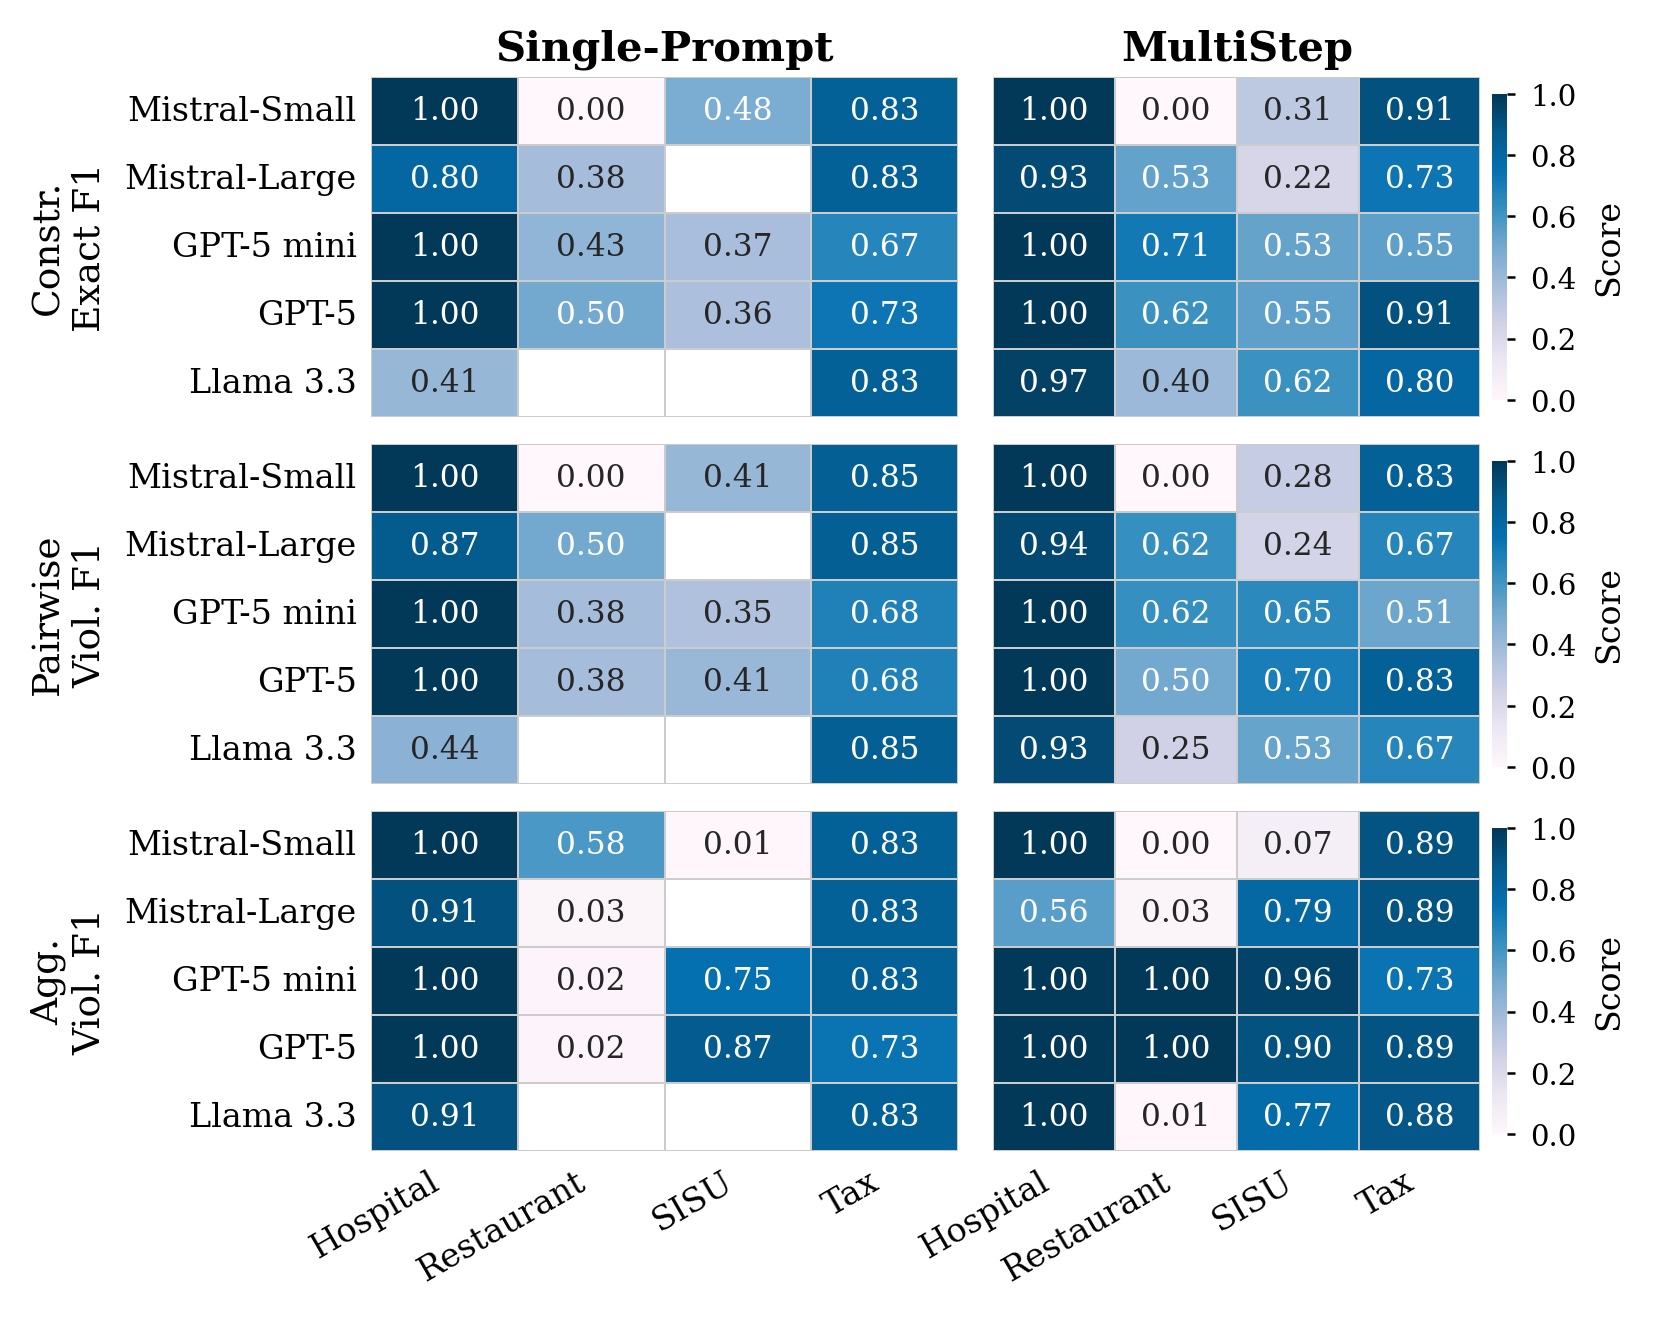

Saved heatmap to `best_model_heatmap.pdf` and `best_model_heatmap.png`

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# ── Publication style ──────────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":       "serif",
    "font.size":         9,
    "axes.titlesize":    10,
    "axes.labelsize":    9,
    "xtick.labelsize":   8,
    "ytick.labelsize":   8,
    "legend.fontsize":   8,
    "figure.dpi":        300,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "text.usetex":       False,   # set True if LaTeX is available
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

main_metrics = ["constraint_exact_f1", "pairwise_viol_f1_mean", "agg_viol_f1"]
metric_labels = {
    "constraint_exact_f1":   "Constr.\nExact F1",
    "pairwise_viol_f1_mean": "Pairwise\nViol. F1",
    "agg_viol_f1":           "Agg.\nViol. F1",
}

# ColorBrewer YlOrRd — prints well in grayscale
cmap = "YlOrRd"
cmap = "Set2"
cmap = "crest"
cmap = "mako"
cmap = "rocket_r"
cmap = "YlGnBu"
cmap = "PuBu"






# Ordered model / dataset display lists (depend on cell 1 variables)
ordered_models   = [model_display[m]   for m in models   if m in model_display]
ordered_datasets = [dataset_display[d] for d in datasets if d in dataset_display]

n_impl    = len(IMPLEMENTATION_ORDER)
n_metrics = len(main_metrics)

# ── Grid: rows = metrics, cols = implementations ───────────────────────────────
fig, axes = plt.subplots(
    n_metrics, n_impl,
    figsize=(2.6 * n_impl, 1.55 * n_metrics),
    gridspec_kw={"hspace": 0.08, "wspace": 0.06},
)

# Guarantee 2-D indexing
if n_metrics == 1:
    axes = [axes]
if n_impl == 1:
    axes = [[row] for row in axes]

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

for row_idx, metric in enumerate(main_metrics):
    for col_idx, impl in enumerate(IMPLEMENTATION_ORDER):
        ax = axes[row_idx][col_idx]

        df_impl = df[df["implementation_canonical"] == impl].copy()
        df_impl["model_d"]   = df_impl["model"].map(model_display)
        df_impl["dataset_d"] = df_impl["dataset"].map(dataset_display)

        heat_data = (
            df_impl.groupby(["model_d", "dataset_d"])[metric]
            .mean()
            .unstack("dataset_d")
            .reindex(index=ordered_models, columns=ordered_datasets)
        )

        annot = heat_data.apply(lambda col: col.map(_fmt))

        show_xticklabels = (row_idx == n_metrics - 1)
        show_yticklabels = (col_idx == 0)
        show_cbar        = (col_idx == n_impl - 1)

        sns.heatmap(
            heat_data,
            ax=ax,
            annot=annot,
            fmt="",
            cmap=cmap,
            vmin=0.0,
            vmax=1.0,
            linewidths=0.4,
            linecolor="#cccccc",
            cbar=show_cbar,
            cbar_kws={"shrink": 0.9, "label": "Score", "pad": 0.02},
            xticklabels=show_xticklabels,
            yticklabels=show_yticklabels,
            annot_kws={"size": 7.5},
        )

        # Implementation name as column title (top row only)
        if row_idx == 0:
            ax.set_title(IMPLEMENTATION_DISPLAY.get(impl, impl), fontweight="bold", pad=4)

        # Metric label on leftmost column only
        if show_yticklabels:
            ax.set_ylabel(metric_labels[metric], labelpad=4)
        else:
            ax.set_ylabel("")

        ax.set_xlabel("")

        # Rotate x-tick labels on bottom row only
        if show_xticklabels:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")

        # Keep y-tick labels horizontal on leftmost column
        if show_yticklabels:
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

        ax.tick_params(length=0)

        if show_cbar:
            cbar = ax.collections[0].colorbar
            cbar.ax.tick_params(labelsize=7, length=2)
            cbar.set_label("Score", size=8)

plt.savefig("best_model_heatmap.pdf", format="pdf")
plt.savefig("best_model_heatmap.png", format="png")
plt.show()
display(Markdown("Saved heatmap to `best_model_heatmap.pdf` and `best_model_heatmap.png`"))
